# City Magnets: What Draws the Crowds in Yogyakarta?
**The full pipeline, person by person** | Data Engineering, Universitas Gadjah Mada

This notebook follows our project in the order the work was done. Each person picks up the output of the person before them:

| Step | Person | Role | Turns | Into |
| :-: | :--- | :--- | :--- | :--- |
| 1 | Altaf | Data ingestion and temporal cleaning | raw JogjaPulse CSVs and OSM | clean daily and hourly tables (Silver) |
| 2 | Nalen | Geospatial engineering and deduplication | clean grid and OSM facilities | a facility label for every cell (Silver) |
| 3 | Rafi | Mobility analytics and statistics | Silver tables | metrics with uncertainty (Gold) |
| 4 | Akhnaf | Visualization and demo video production | Gold tables and visual outputs | four research figures, the interactive map, and the five-minute demo video |

**How to run.** In Google Colab choose **Runtime > Run all**. The notebook downloads our code from GitHub and the JogjaPulse data from Zenodo, then runs every step for real. It takes about 3 minutes.

## Setup
We get the project code, the two JogjaPulse files (about 23 MB) and any missing library.

In [ ]:
import os
import subprocess
import sys
import importlib.util
import urllib.request
from pathlib import Path

if not Path("src/spatial_join.py").exists():
    if not Path("Human-Mobility").exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/altafparves/Human-Mobility.git"], check=True)
    os.chdir("Human-Mobility")
sys.path.insert(0, os.getcwd())

packages = {"geopandas": "geopandas", "pyarrow": "pyarrow", "duckdb": "duckdb", "yaml": "pyyaml", "seaborn": "seaborn"}
missing = [pip for module, pip in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

zenodo = "https://zenodo.org/api/records/23157460/files/{}/content"
for name in ["presence_cell500m_daily.csv", "presence_kapanewon_hourly.csv"]:
    target = Path("data/raw") / name
    if not target.exists():
        urllib.request.urlretrieve(zenodo.format(name), target)
    print(f"{name}: {target.stat().st_size / 1e6:.1f} MB")

presence_cell500m_daily.csv: 11.3 MB
presence_kapanewon_hourly.csv: 12.2 MB


In [ ]:
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

RAW, SILVER, GOLD = Path("data/raw"), Path("data/silver"), Path("data/gold")


def run_step(module):
    subprocess.run([sys.executable, "-m", module], check=True, capture_output=True, text=True)
    print(f"{module} finished")

---
# Altaf: Data Ingestion and Temporal Cleaning
**Goal.** Turn the raw JogjaPulse files into clean, trustworthy tables that everyone else can build on.

### 1.1 What the raw data looks like
The daily file has one row per cell per day with only a cell id, coordinates, a date and `n_maids` (the number of distinct devices). It has no facility names. Cells with fewer than 5 devices are hidden for privacy.

In [ ]:
raw_daily = pd.read_csv(RAW / "presence_cell500m_daily.csv")
raw_hourly = pd.read_csv(RAW / "presence_kapanewon_hourly.csv")
print(f"Daily grid: {len(raw_daily):,} rows | {raw_daily['cell_id'].nunique():,} cells | {raw_daily['date'].nunique()} days")
print(f"Hourly kapanewon: {len(raw_hourly):,} rows | {raw_hourly['kapanewon_code'].nunique()} kapanewon")
expected = raw_daily["cell_id"].nunique() * raw_daily["date"].nunique()
print(f"Published cell-days: {len(raw_daily) / expected:.1%} of all possible cell-days")
raw_daily.head()

Daily grid: 183,548 rows | 5,715 cells | 151 days
Hourly kapanewon: 230,418 rows | 78 kapanewon
Published cell-days: 21.3% of all possible cell-days


,cell_id,x_min_utm,y_min_utm,centroid_lon,centroid_lat,date,n_maids
0,E786_N18255,393000,9127500,110.031602,-7.889900,2021-12-01,9
1,E789_N18259,394500,9129500,110.045250,-7.871843,2021-12-01,7
2,E790_N18255,395000,9127500,110.049744,-7.889942,2021-12-01,17
3,E791_N18254,395500,9127000,110.054269,-7.894474,2021-12-01,5
4,E792_N18252,396000,9126000,110.058784,-7.903529,2021-12-01,20


### 1.2 The main problem: the sample changes
If we add up all devices per day, the total drops suddenly on 1 January and 16 February 2022. People did not disappear. The data provider changed its panel. Any analysis on raw counts would mistake this for a real change in crowds.

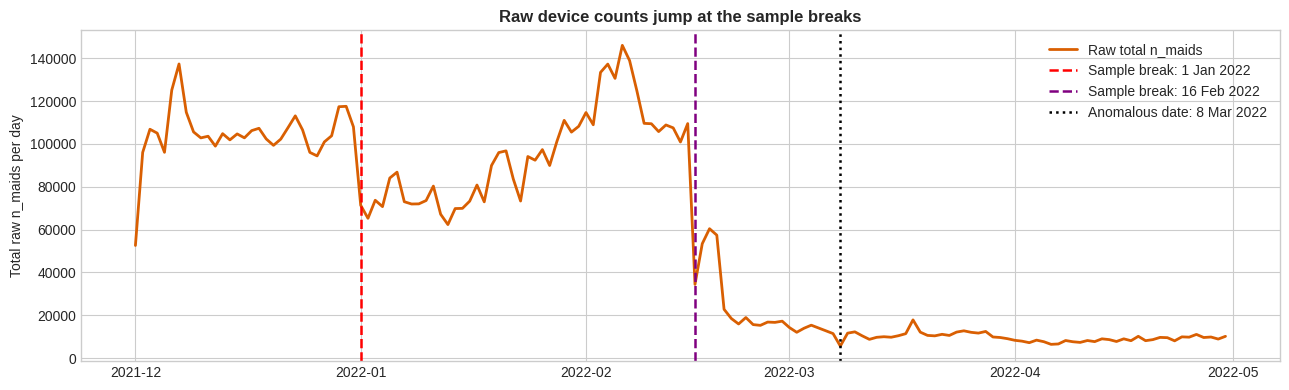

In [ ]:
raw_by_date = raw_daily.groupby("date", as_index=False).agg(total_maids=("n_maids", "sum"))
raw_by_date["date"] = pd.to_datetime(raw_by_date["date"])

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(raw_by_date["date"], raw_by_date["total_maids"], color="#d95f02", lw=2, label="Raw total n_maids")
ax.axvline(pd.Timestamp("2022-01-01"), color="red", ls="--", lw=1.8, label="Sample break: 1 Jan 2022")
ax.axvline(pd.Timestamp("2022-02-16"), color="purple", ls="--", lw=1.8, label="Sample break: 16 Feb 2022")
ax.axvline(pd.Timestamp("2022-03-08"), color="black", ls=":", lw=1.8, label="Anomalous date: 8 Mar 2022")
ax.set_title("Raw device counts jump at the sample breaks", fontsize=12, fontweight="bold")
ax.set_ylabel("Total raw n_maids per day")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 1.3 What Altaf built
* **Verified the files** and saved one row per grid cell with its exact UTM bounds.
* **Extracted OpenStreetMap facilities** and checked six landmarks (UGM, UNY, Ambarrukmo Plaza, Pakuwon Mall, RSUP Dr. Sardjito, Malioboro). The OSM snapshot is stored in the repository, so this notebook does not query OSM again.
* **Added calendar flags**: WIB dates, weekend, the Christmas and New Year window, the sample breaks and the sampling period (December, January, 1 to 15 February, 16 to 28 February).
* **Measured publication coverage**: for every cell and period, the share of expected weekdays and weekends that were actually published.
* **Computed the presence share**, which fixes the sample break problem:

$$\text{Presence Share}_{c,d} = \frac{n\_maids_{c,d}}{\sum_c n\_maids_{c,d}} \times 100$$

In [ ]:
from src.ingest import verify_jogjapulse_datasets

verify_jogjapulse_datasets()
run_step("src.clean_temporal")
sorted(p.name for p in SILVER.iterdir() if p.suffix in {".parquet", ".json"})

src.clean_temporal finished


['cell_coverage_audit.parquet',
 'daily_coverage_summary.parquet',
 'grid_cells_unique.parquet',
 'kapanewon_coverage_audit.parquet',
 'kapanewon_hourly_clean.parquet',
 'mobility_daily_clean.parquet',
 'temporal_cleaning_summary.json']

### 1.4 Landmark audit
Before using OSM, Altaf checked that the city's best known places were really in the data.

In [ ]:
audit = json.loads((RAW / "osm_landmark_audit.json").read_text(encoding="utf-8"))
landmarks = pd.DataFrame([
    {"Landmark": name, "Expected category": v["expected_category"], "Captured": v["current_captured"],
     "OSM elements": v["current_total_elements"], "Example names": ", ".join(v["current_names_sample"][:3])}
    for name, v in audit["landmark_comparison_summary"].items()
])
landmarks

,Landmark,Expected category,Captured,OSM elements,Example names
0,UGM,education_campus,True,48,"Balairung UGM, Bundaran UGM, Fakultas Ekonomika dan Bisn..."
1,UNY,education_campus,True,31,"Asrama Mahasiswa UNY Kampus Wates, FIP UNY, Fakultas Eko..."
2,Ambarrukmo_Plaza,commercial_mall,True,7,"Ambarrukmo Plaza 1, Ambarrukmo Plaza 2, Halte Ambarrukmo..."
3,Pakuwon_Hartono_Mall,commercial_mall,True,8,"Halte Pakuwon Mall Jogja, Pakuwon Mall, Pakuwon Mall 2"
4,RSUP_Dr_Sardjito,healthcare_hospital,True,8,"Halte RS Sardjito (Barat), Halte RS Sardjito (Timur), IC..."
5,Malioboro,tourism_site / commercial_mall,True,16,"Halte Malioboro 1, Halte Malioboro 2, Jalan Malioboro"


### 1.5 Before and after
The raw file had 7 columns. The cleaned table adds the calendar flags, coverage flags and presence shares.

In [ ]:
silver_daily = pd.read_parquet(SILVER / "mobility_daily_clean.parquet")
print(f"Clean daily table: {silver_daily.shape[0]:,} rows x {silver_daily.shape[1]} columns (raw had {raw_daily.shape[1]})")
silver_daily[["cell_id", "date", "n_maids", "day_name", "is_weekend", "is_nataru_window",
              "sampling_period", "pass_90_in_period", "published_presence_share_pct"]].head()

Clean daily table: 183,548 rows x 50 columns (raw had 7)


,cell_id,date,n_maids,day_name,is_weekend,is_nataru_window,sampling_period,pass_90_in_period,published_presence_share_pct
0,E786_N18255,2021-12-01,9,Wednesday,False,False,2021_Dec,False,0.017109
1,E789_N18259,2021-12-01,7,Wednesday,False,False,2021_Dec,False,0.013307
2,E790_N18255,2021-12-01,17,Wednesday,False,False,2021_Dec,False,0.032318
3,E791_N18254,2021-12-01,5,Wednesday,False,False,2021_Dec,False,0.009505
4,E792_N18252,2021-12-01,20,Wednesday,False,False,2021_Dec,True,0.038021


The chart below follows the busiest cell. Its share (green) is calm through December and January. After 16 February the lower panel shows coverage collapsing, so the few cells still published each hold a much larger share. This is why shares are only compared within one period, never across a break.

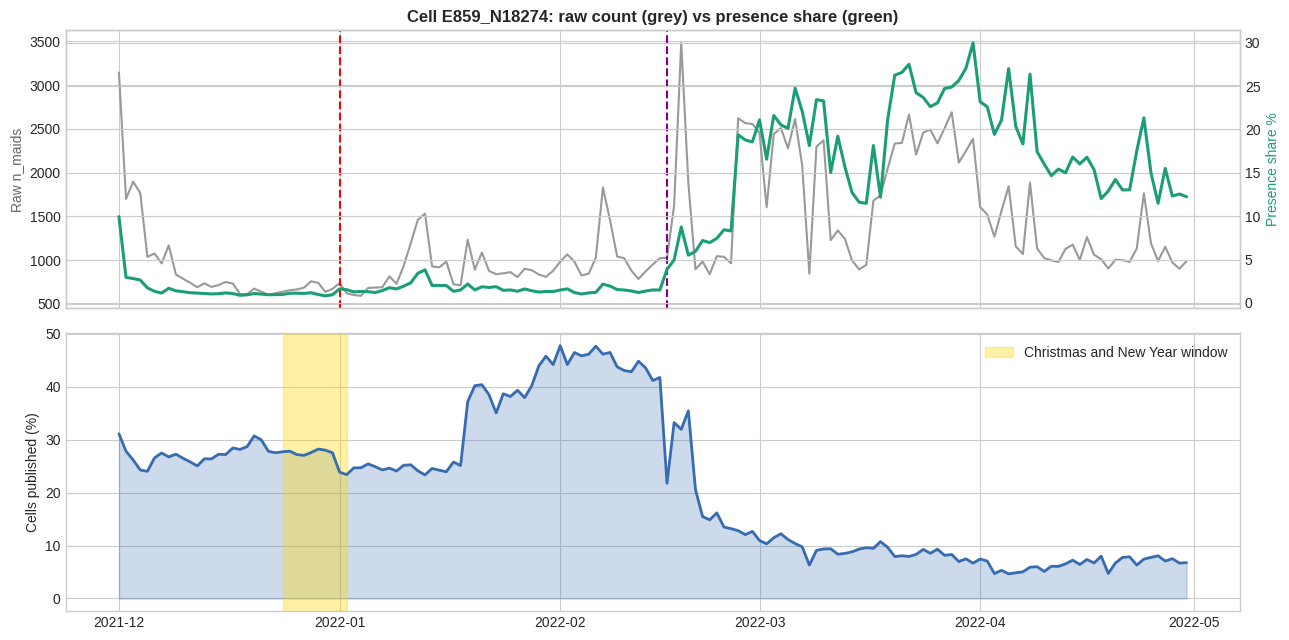

In [ ]:
daily_sum = pd.read_parquet(SILVER / "daily_coverage_summary.parquet")
daily_sum["date"] = pd.to_datetime(daily_sum["date"])
top_cell = silver_daily.groupby("cell_id")["n_maids"].median().idxmax()
cell_ts = silver_daily[silver_daily["cell_id"] == top_cell].sort_values("date_wib")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
twin = ax1.twinx()
ax1.plot(cell_ts["date_wib"].dt.tz_localize(None), cell_ts["n_maids"], color="#999999", lw=1.5)
twin.plot(cell_ts["date_wib"].dt.tz_localize(None), cell_ts["published_presence_share_common90_pct"], color="#1b9e77", lw=2.2)
for d, c in [("2022-01-01", "red"), ("2022-02-16", "purple")]:
    ax1.axvline(pd.Timestamp(d), color=c, ls="--")
ax1.set_title(f"Cell {top_cell}: raw count (grey) vs presence share (green)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Raw n_maids", color="#666666")
twin.set_ylabel("Presence share %", color="#1b9e77")
ax2.fill_between(daily_sum["date"], daily_sum["daily_cell_coverage_pct"], color="#386cb0", alpha=0.25)
ax2.plot(daily_sum["date"], daily_sum["daily_cell_coverage_pct"], color="#386cb0", lw=2)
ax2.axvspan(pd.Timestamp("2021-12-24"), pd.Timestamp("2022-01-02"), color="gold", alpha=0.35, label="Christmas and New Year window")
ax2.set_ylabel("Cells published (%)")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 1.6 The coverage rule
A cell is only compared if it was published on at least 90% of its expected weekdays and weekends in that period. 80% and 95% are kept as sensitivity checks.

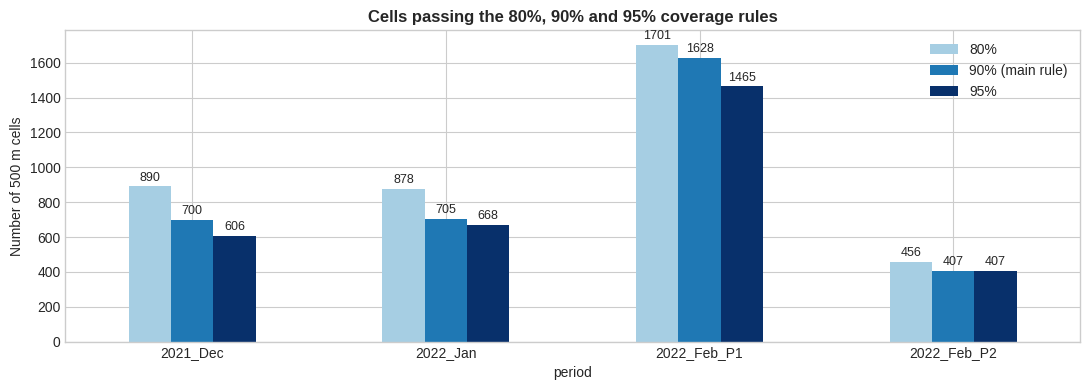

In [ ]:
cov = pd.read_parquet(SILVER / "cell_coverage_audit.parquet")
periods = ["2021_Dec", "2022_Jan", "2022_Feb_P1", "2022_Feb_P2"]
cov_summary = cov[cov["period"].isin(periods)].groupby("period")[["pass_80_ordinary", "pass_90_ordinary", "pass_95_ordinary"]].sum().reindex(periods)
ax = cov_summary.plot(kind="bar", figsize=(11, 4), color=["#a6cee3", "#1f78b4", "#08306b"], rot=0)
ax.set_title("Cells passing the 80%, 90% and 95% coverage rules", fontsize=12, fontweight="bold")
ax.set_ylabel("Number of 500 m cells")
ax.legend(["80%", "90% (main rule)", "95%"])
for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=2)
plt.tight_layout()
plt.show()

### Interpretation of Altaf
* Only about **21% of all cell-days are published**. The hidden ones are mostly quiet rural cells, so the data leans toward busy urban areas.
* The **sample breaks are real and large**. The presence share removes the change in total devices, but not the change in which cells are published, so every comparison stays inside one period.
* The **90% coverage rule keeps a few hundred to about 1,600 cells per period**. Every later result is about these well observed places, not the whole province.
* **All six landmarks were found** in OSM, so the facility data is usable for the next step.

---
# Nalen: Geospatial Engineering and Facility Deduplication
**Goal.** Find out which facilities are inside each 500 m cell, counting every real place once.

### 2.1 The problem: one place, many drawings
OSM volunteers draw the same place many times. A campus can be one big outline plus a point for every faculty and bus stop inside it. If we counted every drawing, UGM would count as dozens of campuses.

src.spatial_join finished


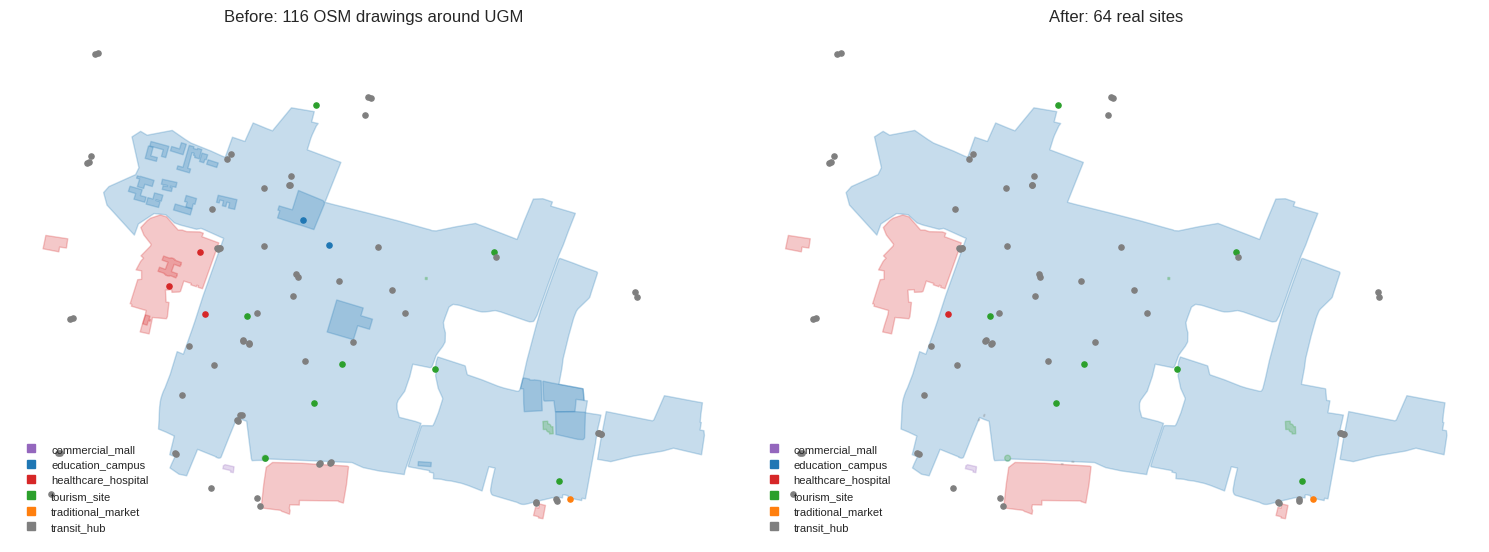

In [ ]:
run_step("src.spatial_join")

from src.spatial_join import build_grid_polygons

grid = build_grid_polygons(pd.read_parquet(SILVER / "grid_cells_unique.parquet"))
raw_osm = gpd.read_parquet(SILVER / "osm_facilities_parsed.parquet")
sites = gpd.read_parquet(SILVER / "facilities_dedup.parquet")
links = pd.read_parquet(SILVER / "cell_facility_links.parquet")
cells_tbl = pd.read_parquet(SILVER / "grid_facilities.parquet")
dedup_log = json.loads((SILVER / "facilities_dedup_log.json").read_text(encoding="utf-8"))
COLORS = {"education_campus": "#1f77b4", "healthcare_hospital": "#d62728", "commercial_mall": "#9467bd",
          "traditional_market": "#ff7f0e", "tourism_site": "#2ca02c", "transit_hub": "#7f7f7f"}

ugm = sites.loc[sites["name"] == "Universitas Gadjah Mada"].iloc[0]
xmin, ymin, xmax, ymax = ugm.geometry.buffer(300).bounds


def draw_features(ax, gdf, category_col, title):
    for cat, part in gdf.groupby(category_col):
        polys = part[part.geom_type.isin(["Polygon", "MultiPolygon"])]
        others = part[~part.geom_type.isin(["Polygon", "MultiPolygon"])]
        if len(polys):
            polys.plot(ax=ax, facecolor=COLORS[cat], edgecolor=COLORS[cat], alpha=0.25)
        if len(others):
            others.plot(ax=ax, color=COLORS[cat], markersize=14)
        ax.plot([], [], "s", color=COLORS[cat], label=cat)
    ax.set_title(title)
    ax.legend(loc="lower left", fontsize=8)
    ax.set_axis_off()


raw_ugm = raw_osm.explode("categories").rename(columns={"categories": "category"}).cx[xmin:xmax, ymin:ymax]
sites_ugm = sites.cx[xmin:xmax, ymin:ymax]
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
draw_features(axes[0], raw_ugm, "category", f"Before: {len(raw_ugm)} OSM drawings around UGM")
draw_features(axes[1], sites_ugm, "category", f"After: {len(sites_ugm)} real sites")
plt.tight_layout()
plt.show()

### 2.2 Deduplication rules
Two drawings of the same category become one **site** when any rule holds. Links chain together, so A linked to B and B linked to C makes one site.

| Rule | Meaning | Example |
| :--- | :--- | :--- |
| contained | One drawing sits inside the other's outline | Faculty points inside the UGM campus |
| same name | Same name and within 500 m | The 11 buildings of Pasar Rogobangsan |
| transit | Two transit drawings within 20 m | One bus stop drawn as a sign, a stop position and a platform |

Former train stops that are now attractions count as tourism only, because they draw visitors, not commuters.

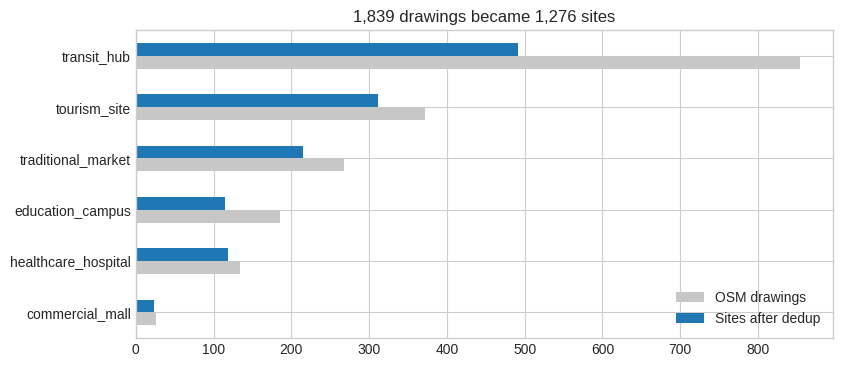

Links made by each rule: {'same_name': 424, 'transit': 318, 'contained': 191}


In [ ]:
compare = pd.DataFrame({"OSM drawings": pd.Series(dedup_log["features_by_category"]),
                        "Sites after dedup": pd.Series(dedup_log["sites_by_category"])}).sort_values("OSM drawings")
ax = compare.plot.barh(figsize=(9, 4), color=["#c7c7c7", "#1f77b4"])
ax.set_title(f"{compare['OSM drawings'].sum():,} drawings became {compare['Sites after dedup'].sum():,} sites")
plt.show()
print("Links made by each rule:", dedup_log["links_by_rule"])

### 2.3 Placing sites on the grid
Each cell is rebuilt as an exact 500 m square in UTM zone 49S (EPSG:32749), a projection measured in metres. Polygons are cut by the grid and we keep the area inside each cell. A point goes to the one cell that contains it. A big site reaches many cells:

$$s_{cell}(S,C) = \frac{A(S \cap C)}{250{,}000\ \text{m}^2} \qquad s_{site}(S,C) = \frac{A(S \cap C)}{A(S)}$$

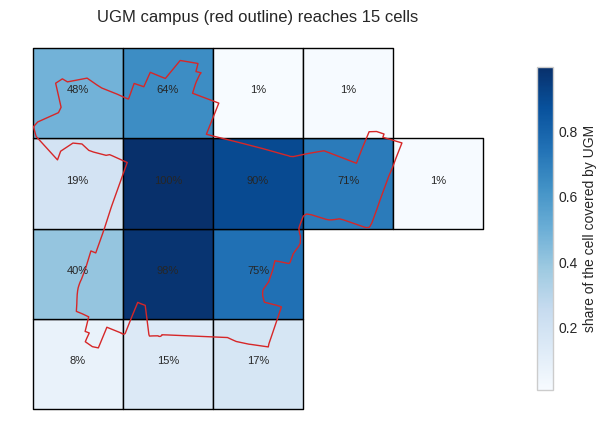

In [ ]:
ugm_links = gpd.GeoDataFrame(links[links["site_id"] == ugm["site_id"]].merge(grid[["cell_id", "geometry"]], on="cell_id"),
                             geometry="geometry", crs=grid.crs)
fig, ax = plt.subplots(figsize=(8, 7))
ugm_links.plot(ax=ax, column="overlap_share_of_cell", cmap="Blues", edgecolor="black", legend=True,
               legend_kwds={"label": "share of the cell covered by UGM", "shrink": 0.6})
gpd.GeoSeries([ugm.geometry], crs=grid.crs).boundary.plot(ax=ax, color="#d62728", linewidth=1)
for _, r in ugm_links.iterrows():
    ax.annotate(f"{r.overlap_share_of_cell:.0%}", (r.geometry.centroid.x, r.geometry.centroid.y), ha="center", fontsize=8)
ax.set_title(f"UGM campus (red outline) reaches {len(ugm_links)} cells")
ax.set_axis_off()
plt.show()

### 2.4 The sliver rule
Tiny overlaps should not label a cell. A 25 m² corner of the RSUP Dr. Sardjito outline crosses into a UGM cell, and counting it would make that cell look like a campus plus hospital cell. So a polygon counts in a cell only if it covers at least **5% of the cell**, or at least **50% of the site** is there, or it is the site's **home cell** (its largest piece). Points always count.

In [ ]:
names = sites.set_index("site_id")["name"]
links[links["cell_id"] == "E862_N18282"].assign(name=lambda d: d["site_id"].map(names))[
    ["name", "category", "link_kind", "overlap_m2", "overlap_share_of_cell", "counts_for_cell"]].round(3)

,name,category,link_kind,overlap_m2,overlap_share_of_cell,counts_for_cell
756,Universitas Gadjah Mada,education_campus,polygon,248995.950,0.996,True
757,RSUP Dr. Sardjito,healthcare_hospital,polygon,25.452,0.000,False
758,Bio-Paleoanthropology Museum,tourism_site,point,0.000,0.000,True
759,Halte RS Sardjito (Timur),transit_hub,point,0.000,0.000,True
760,Halte GSP,transit_hub,point,0.000,0.000,True
761,Halte Jalan Medika,transit_hub,point,0.000,0.000,True
762,Halte F. MIPA,transit_hub,point,0.000,0.000,True
763,GSP UGM (Barat),transit_hub,point,0.000,0.000,True


### 2.5 Labelling every cell
Every cell gets a class from the five destination categories (campus, hospital, mall, market, tourism). Transit is kept as a separate flag, because bus stops are almost everywhere and would make most city cells look mixed. **Baseline candidates** are cells without a selected facility within 2 km of a facility cell, used later as a fair comparison group.

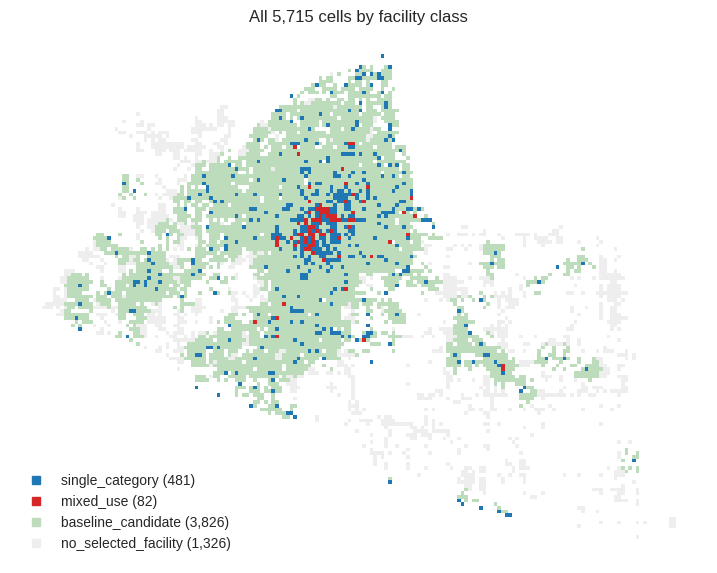

In [ ]:
cells_geo = gpd.GeoDataFrame(cells_tbl, geometry=build_grid_polygons(cells_tbl).geometry, crs=grid.crs)
cells_geo["map_class"] = cells_geo["cell_class"].where(cells_geo["cell_class"] != "no_selected_facility",
                                                       np.where(cells_geo["is_baseline_candidate"], "baseline_candidate", "no_selected_facility"))
CLASS_COLORS = {"single_category": "#1f77b4", "mixed_use": "#d62728", "baseline_candidate": "#bcdcbc", "no_selected_facility": "#eeeeee"}
fig, ax = plt.subplots(figsize=(9, 9))
for cls, color in CLASS_COLORS.items():
    part = cells_geo[cells_geo["map_class"] == cls]
    part.plot(ax=ax, color=color)
    ax.plot([], [], "s", color=color, label=f"{cls} ({len(part):,})")
ax.set_title("All 5,715 cells by facility class")
ax.legend(loc="lower left")
ax.set_axis_off()
plt.show()

### Interpretation of Nalen
* About **a third of the OSM drawings were duplicates** (1,839 drawings became 1,276 sites). Without this step, big campuses and stations would be heavily over counted.
* Large sites **span many cells** (UGM reaches 15). Those cells share the same visitors, so Rafi treats them as one cluster when measuring uncertainty.
* Only **563 cells hold a destination facility** (481 single category, 82 mixed use). Most of the province has none of the selected facilities mapped.
* Mixed use cells are kept explicit, so later results can be checked on single category cells only.

---
# Rafi: Mobility Analytics and Statistical Modelling
**Goal.** Turn the Silver tables into metrics that answer the research questions, with honest uncertainty.

### 3.1 Cell metrics
For every eligible cell and period, Rafi computes the weekday and weekend presence shares using ordinary days only (the holiday window is removed), and their ratio:

$$\text{Ratio}_c = \frac{\overline{\text{share}}_{c,\ \text{weekday}}}{\overline{\text{share}}_{c,\ \text{weekend}}}$$

A ratio above 1 means the cell is relatively busier on weekdays. A cell belongs to every category it holds, using Nalen's `has_` flags.

In [ ]:
run_step("src.metrics")
gold_summary = json.loads((GOLD / "gold_metrics_summary.json").read_text(encoding="utf-8"))
cell_metrics = pd.read_parquet(GOLD / "cell_metrics.parquet")
print(f"{len(cell_metrics):,} cell-periods over {gold_summary['distinct_clusters']:,} site clusters")
cell_metrics[["cell_id", "sampling_period", "restricted_share_weekday", "restricted_share_weekend",
              "wd_we_ratio_restricted", "cell_class", "primary_category", "cluster_id"]].head()

src.metrics finished
3,576 cell-periods over 1,639 site clusters


,cell_id,sampling_period,restricted_share_weekday,restricted_share_weekend,wd_we_ratio_restricted,cell_class,primary_category,cluster_id
0,E790_N18256,2022_Feb_P1,0.009373,0.009964,0.940723,no_selected_facility,None,E790_N18256
1,E791_N18256,2022_Feb_P1,0.010027,0.013855,0.723705,no_selected_facility,None,E791_N18256
2,E792_N18252,2021_Dec,0.070360,0.055007,1.279110,no_selected_facility,None,E792_N18252
3,E792_N18252,2022_Feb_P1,0.043102,0.044962,0.958635,no_selected_facility,None,E792_N18252
4,E792_N18252,2022_Jan,0.077796,0.075704,1.027638,no_selected_facility,None,E792_N18252


### 3.2 Uncertainty that respects shared sites
Neighbouring cells of one campus are not independent, so Rafi resamples **whole site clusters**, not single cells. He repeats this 1,000 times and takes the middle 95% of the medians as the interval.

In [ ]:
print(json.dumps(gold_summary["bootstrap"], indent=2))
summary = pd.read_parquet(GOLD / "category_summary.parquet")
order = ["2021_Dec", "2022_Jan", "2022_Feb_P1", "2022_Feb_P2"]
summary["ratio (95% CI)"] = summary.apply(lambda r: f"{r.median_ratio:.2f} ({r.ci_low:.2f} to {r.ci_high:.2f})", axis=1)
summary.pivot(index="category", columns="sampling_period", values="ratio (95% CI)")[order]

{
  "samples": 1000,
  "seed": 42,
  "cluster_unit": "cluster_id (cells sharing a Role 2 site)",
  "multi_cell_clusters": 135,
  "largest_cluster_cells": 18
}


sampling_period,2021_Dec,2022_Jan,2022_Feb_P1,2022_Feb_P2
category,,,,
baseline_candidate,1.02 (0.99 to 1.06),0.99 (0.96 to 1.01),1.05 (1.03 to 1.06),1.08 (1.05 to 1.11)
commercial_mall,1.37 (1.22 to 1.62),0.89 (0.84 to 0.94),1.10 (1.04 to 1.17),0.96 (0.90 to 1.04)
education_campus,1.29 (1.21 to 1.40),1.02 (0.96 to 1.04),1.15 (1.13 to 1.20),1.14 (1.10 to 1.22)
healthcare_hospital,1.29 (1.15 to 1.47),1.01 (0.96 to 1.04),1.09 (1.05 to 1.17),1.07 (1.01 to 1.20)
tourism_site,1.35 (1.28 to 1.38),0.96 (0.93 to 0.99),1.12 (1.09 to 1.15),1.05 (0.99 to 1.10)
traditional_market,1.22 (1.12 to 1.30),0.97 (0.93 to 1.01),1.06 (1.03 to 1.12),1.03 (0.98 to 1.11)
transit_hub,1.31 (1.23 to 1.36),0.96 (0.94 to 0.97),1.12 (1.10 to 1.15),1.07 (1.04 to 1.11)


### 3.3 Sensitivity checks
A result is only trusted if it survives a change in the rules. Here are campus ratios under the 80%, 90% and 95% coverage rules.

In [ ]:
coverage_sens = pd.read_parquet(GOLD / "coverage_sensitivity.parquet")
coverage_sens[coverage_sens["category"] == "education_campus"].pivot_table(
    index="sampling_period", columns="coverage_threshold", values="median_ratio").reindex(order).round(3)

coverage_threshold,80,90,95
sampling_period,,,
2021_Dec,1.275,1.291,1.236
2022_Jan,1.015,1.022,1.017
2022_Feb_P1,1.154,1.152,1.146
2022_Feb_P2,1.111,1.138,1.138


### 3.4 Matched comparison
To check RQ1 more fairly, each facility cell is paired with a nearby baseline cell that has similar coverage and activity. The table shows the difference in presence share (facility minus match). Rows with fewer than 20 pairs are withheld.

In [ ]:
matched = pd.read_parquet(GOLD / "matched_comparison.parquet")
matched[matched["sampling_period"].isin(["2021_Dec", "2022_Feb_P1"])][
    ["sampling_period", "category", "matched_pairs", "median_difference", "ci_low", "ci_high", "evidence"]].round(3)

,sampling_period,category,matched_pairs,median_difference,ci_low,ci_high,evidence
0,2021_Dec,commercial_mall,3,NaN,NaN,NaN,withheld: fewer than 20 matched pairs
1,2021_Dec,education_campus,66,0.135,-0.046,0.215,observational
2,2021_Dec,healthcare_hospital,25,0.134,-0.044,0.322,observational
3,2021_Dec,tourism_site,31,0.094,-0.142,0.203,observational
4,2021_Dec,traditional_market,28,0.002,-0.291,0.132,observational
5,2021_Dec,transit_hub,34,0.000,0.000,0.169,observational
6,2022_Feb_P1,commercial_mall,15,NaN,NaN,NaN,withheld: fewer than 20 matched pairs
7,2022_Feb_P1,education_campus,100,0.081,-0.002,0.116,observational
8,2022_Feb_P1,healthcare_hospital,83,0.028,-0.064,0.063,observational
9,2022_Feb_P1,tourism_site,100,0.048,-0.003,0.099,observational


### 3.5 Holiday comparison and the 1 January rule
Each holiday date is compared with ordinary dates of the same weekday in the same period. **1 January is always withheld** because of the sample break, and no single holiday uplift number is produced.

In [ ]:
event = pd.read_parquet(GOLD / "event_window.parquet")
print(event["evidence"].value_counts().to_string())
event[event["evidence"] == "exploratory"].pivot_table(index="date", columns="category", values="median_relative_presence").round(2)

evidence
exploratory                           63
withheld: 1 January sampling break     7


category,baseline_candidate,commercial_mall,education_campus,healthcare_hospital,tourism_site,traditional_market,transit_hub
date,,,,,,,
2021-12-24,1.01,1.11,1.05,1.07,1.12,1.00,1.12
2021-12-25,1.12,1.15,1.29,1.17,1.29,1.15,1.23
2021-12-26,1.11,1.28,1.23,1.23,1.20,1.06,1.16
2021-12-27,1.08,0.97,1.05,1.03,1.09,1.00,1.06
2021-12-28,1.06,1.09,1.03,0.99,1.00,0.98,1.03
2021-12-29,0.96,0.66,0.60,0.75,0.64,0.63,0.65
2021-12-30,0.95,0.88,0.77,0.92,0.83,0.82,0.82
2021-12-31,0.98,1.08,0.98,1.04,1.04,1.02,1.04
2022-01-02,0.97,0.64,0.94,0.81,0.88,0.87,0.84


### Interpretation of Rafi
* **Campuses lean weekday** in December (1.29), early February (1.15) and late February (1.14), and their intervals stay above 1. January is flat (1.02, interval crossing 1), matching the semester break.
* The campus result **holds under all three coverage rules** (80%, 90%, 95%), so it is not an artefact of the cut off.
* **The matched comparison is cautious.** After pairing with similar nearby cells, every category's interval includes zero, and mall rows are withheld for too few pairs. Facility cells look busier than average, but not clearly busier than comparable neighbours.
* **Holiday results stay exploratory.** 25 December is above normal for most categories, and 29 December drops for every facility type while baseline cells hardly move, which looks more like a data effect than behaviour.

---
# Akhnaf: Visualization and Demo Video
**Goal.** Turn the Gold tables into figures that answer RQ1 to RQ4 at a glance, plus an interactive map.

The interactive 500 m map is too large to show inside a notebook (about 28 MB). Open it here: **[altafparves.github.io/Human-Mobility](https://altafparves.github.io/Human-Mobility/)**

**Demo video.** Akhnaf produced and edited the five-minute City Magnets demo. It introduces the Yogyakarta map and walks through the four research visuals using animated highlights. [Watch the five-minute City Magnets demo on YouTube](https://youtu.be/YwWwRleElAA).


In [ ]:
from src.visualize import build

map_file, weekly_fig, nataru_fig, hourly_fig, pull_fig = build("2021_Dec", map_period="2022_Feb_P1")
print("Figures written:", [p.name for p in (pull_fig, weekly_fig, nataru_fig, hourly_fig)])
print("Interactive map written:", map_file)


### 4.1 RQ1 Facility Pull
Bars show the median weekday presence share per category. Black lines are the cluster bootstrap intervals and the dashed line is the baseline.

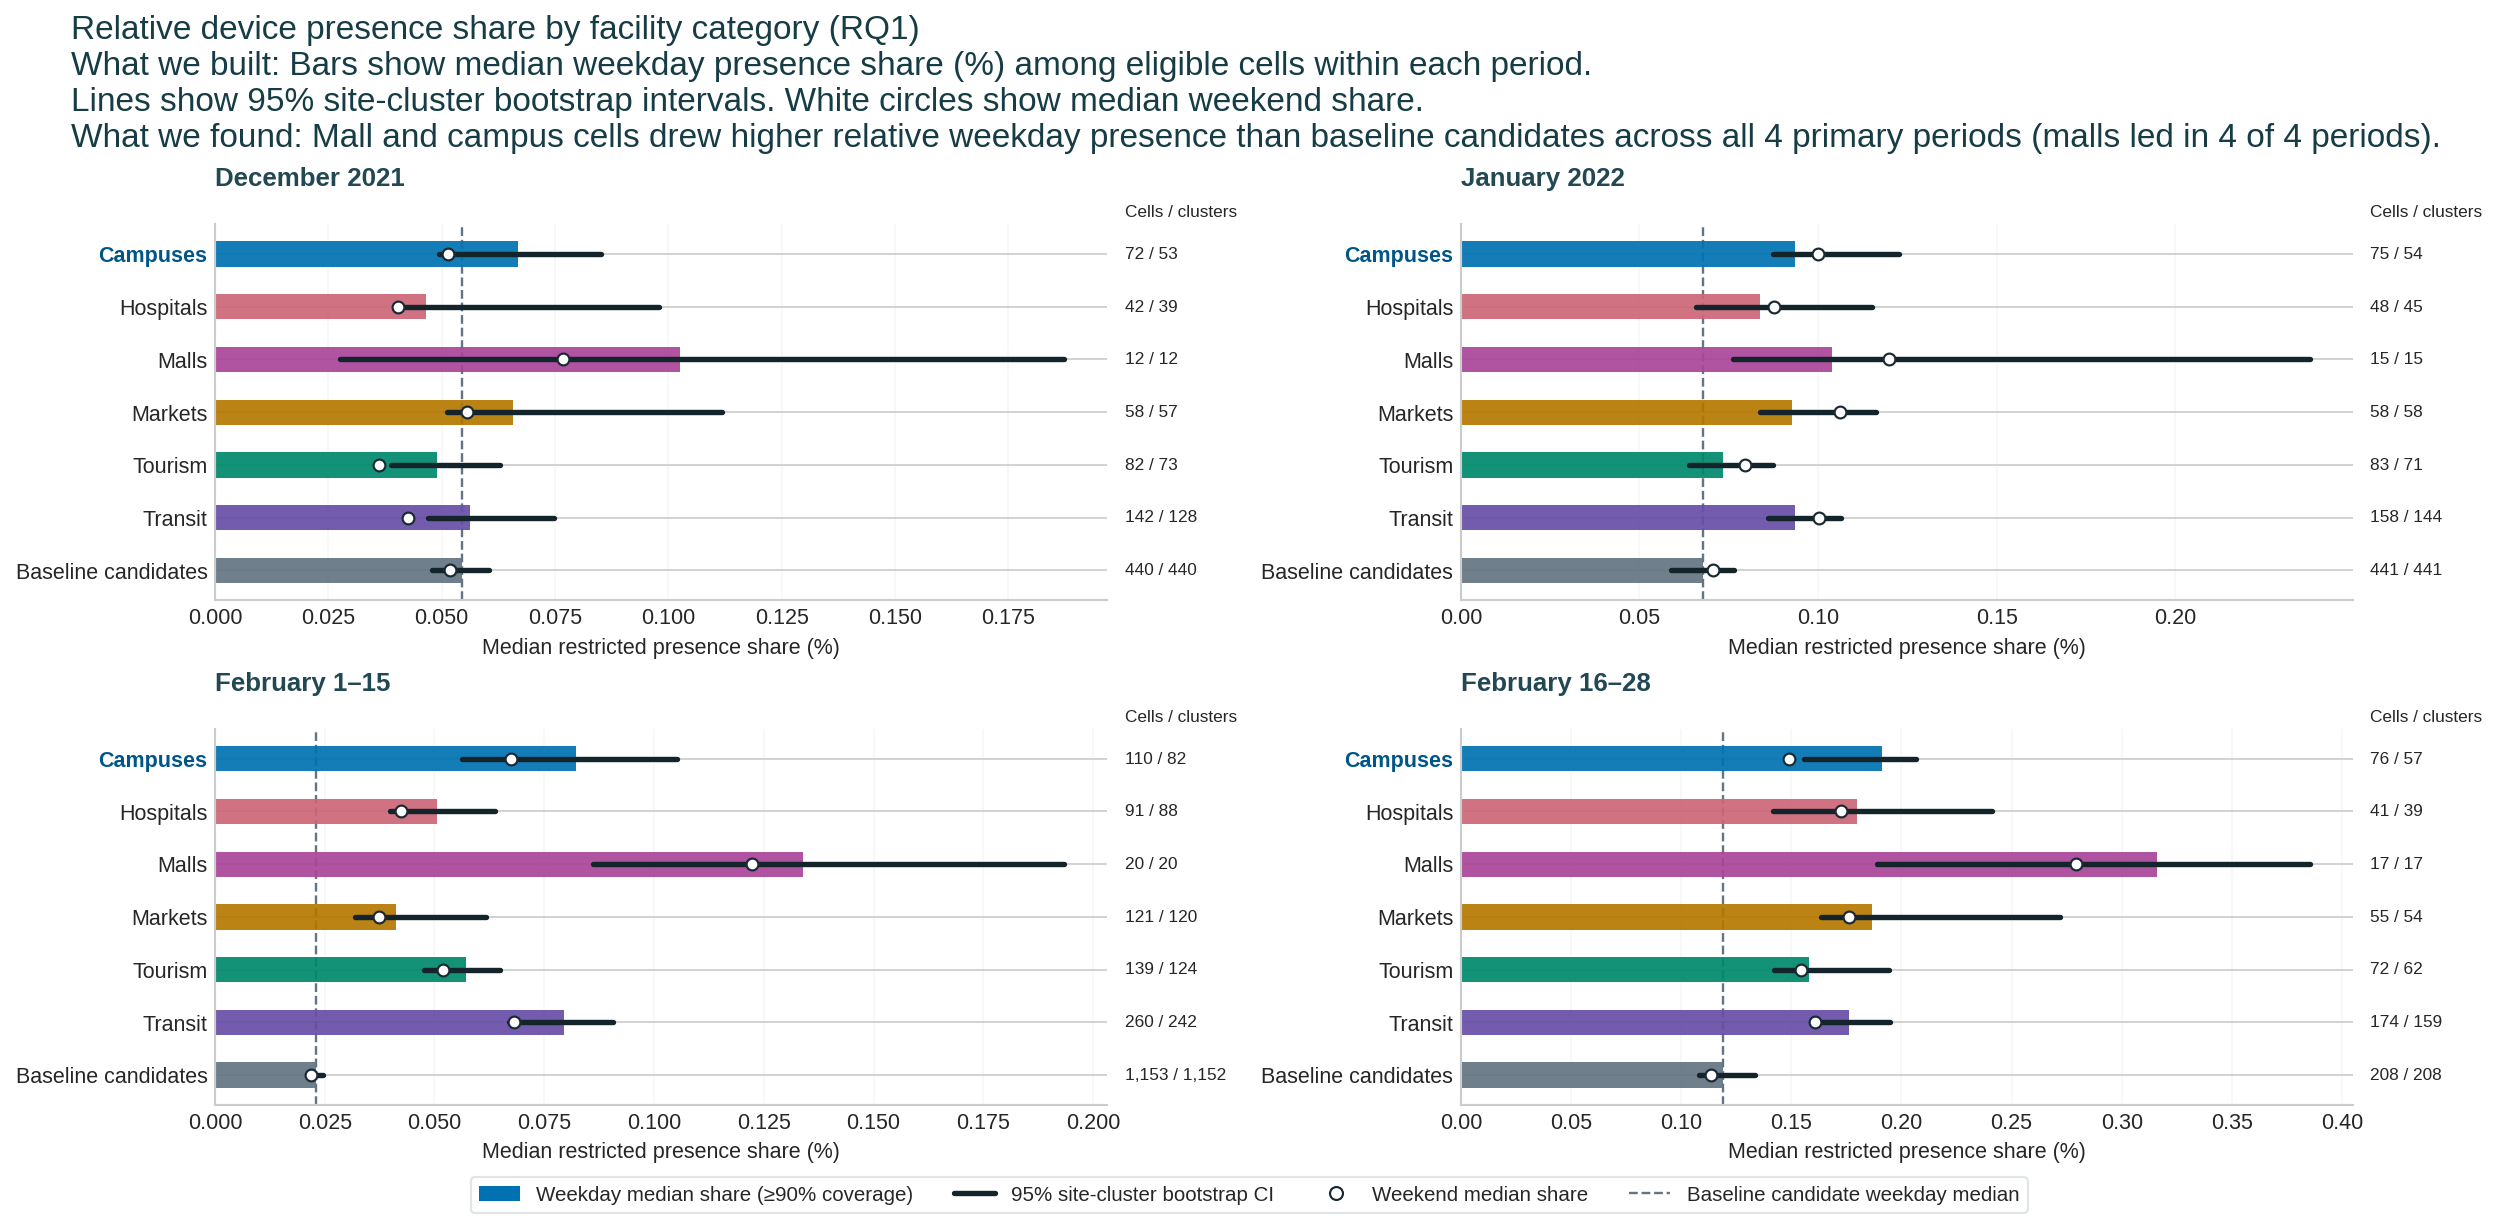

In [ ]:
display(Image(filename=str(pull_fig)))

**Interpretation.** Malls had the highest median weekday presence share in each of the four primary periods, ranging from about **0.10% to 0.32%**. Campus cells also sat above the dashed baseline in every period. Hospitals and tourism cells were slightly below it in December, so the pattern varies by facility type. The horizontal intervals show uncertainty. These are comparisons of observed device presence across cells. The matched analysis in Section 3.4 gives a more cautious comparison with similar nearby cells.


### 4.2 RQ2 Weekly Rhythm
Bars show the weekday to weekend ratio, where 1.0 means equal. Diamonds repeat it for single category cells.

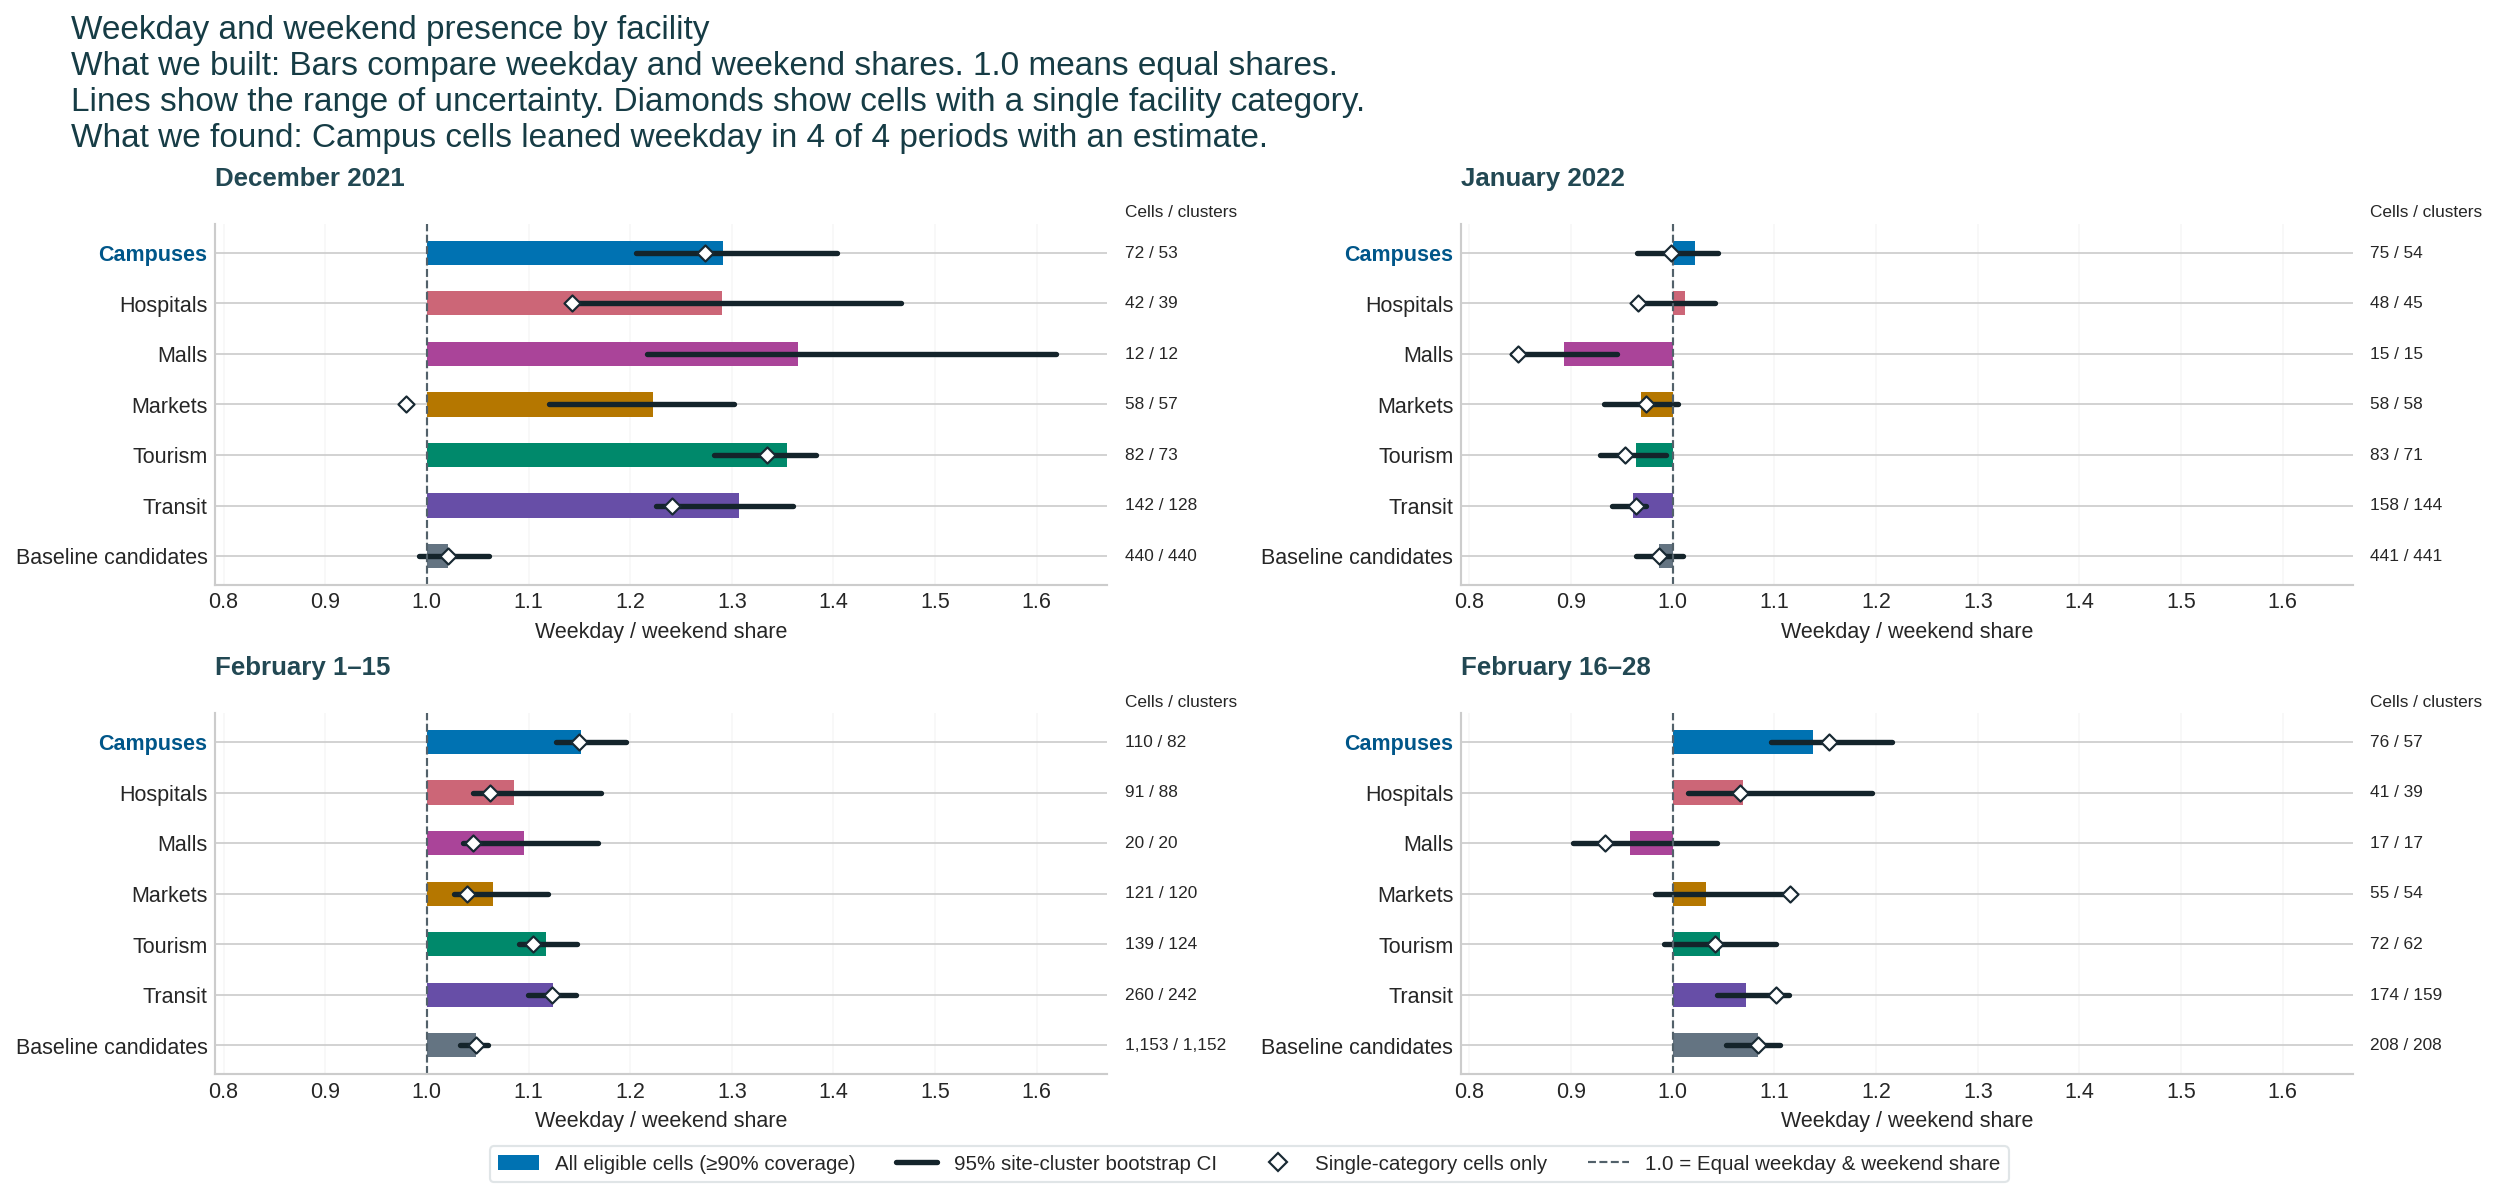

In [ ]:
display(Image(filename=str(weekly_fig)))

**Interpretation.** Campus point estimates were above the **1.0** parity line in all four periods. The December ratio of **1.29** means the median weekday share was about **29% higher** than the weekend share. January was close to parity at **1.02**, and its interval crossed 1.0. Malls, markets, and tourism leaned weekend in January, while the relative gap for hospitals and campuses varied by period. The diamonds show whether the pattern persists when we restrict the comparison to single-category cells.


### 4.3 RQ3 Holiday Shockwave
Lines compare each holiday date with the same weekday outside the holiday. The bottom panel shows daily coverage and the shaded 1 January break.

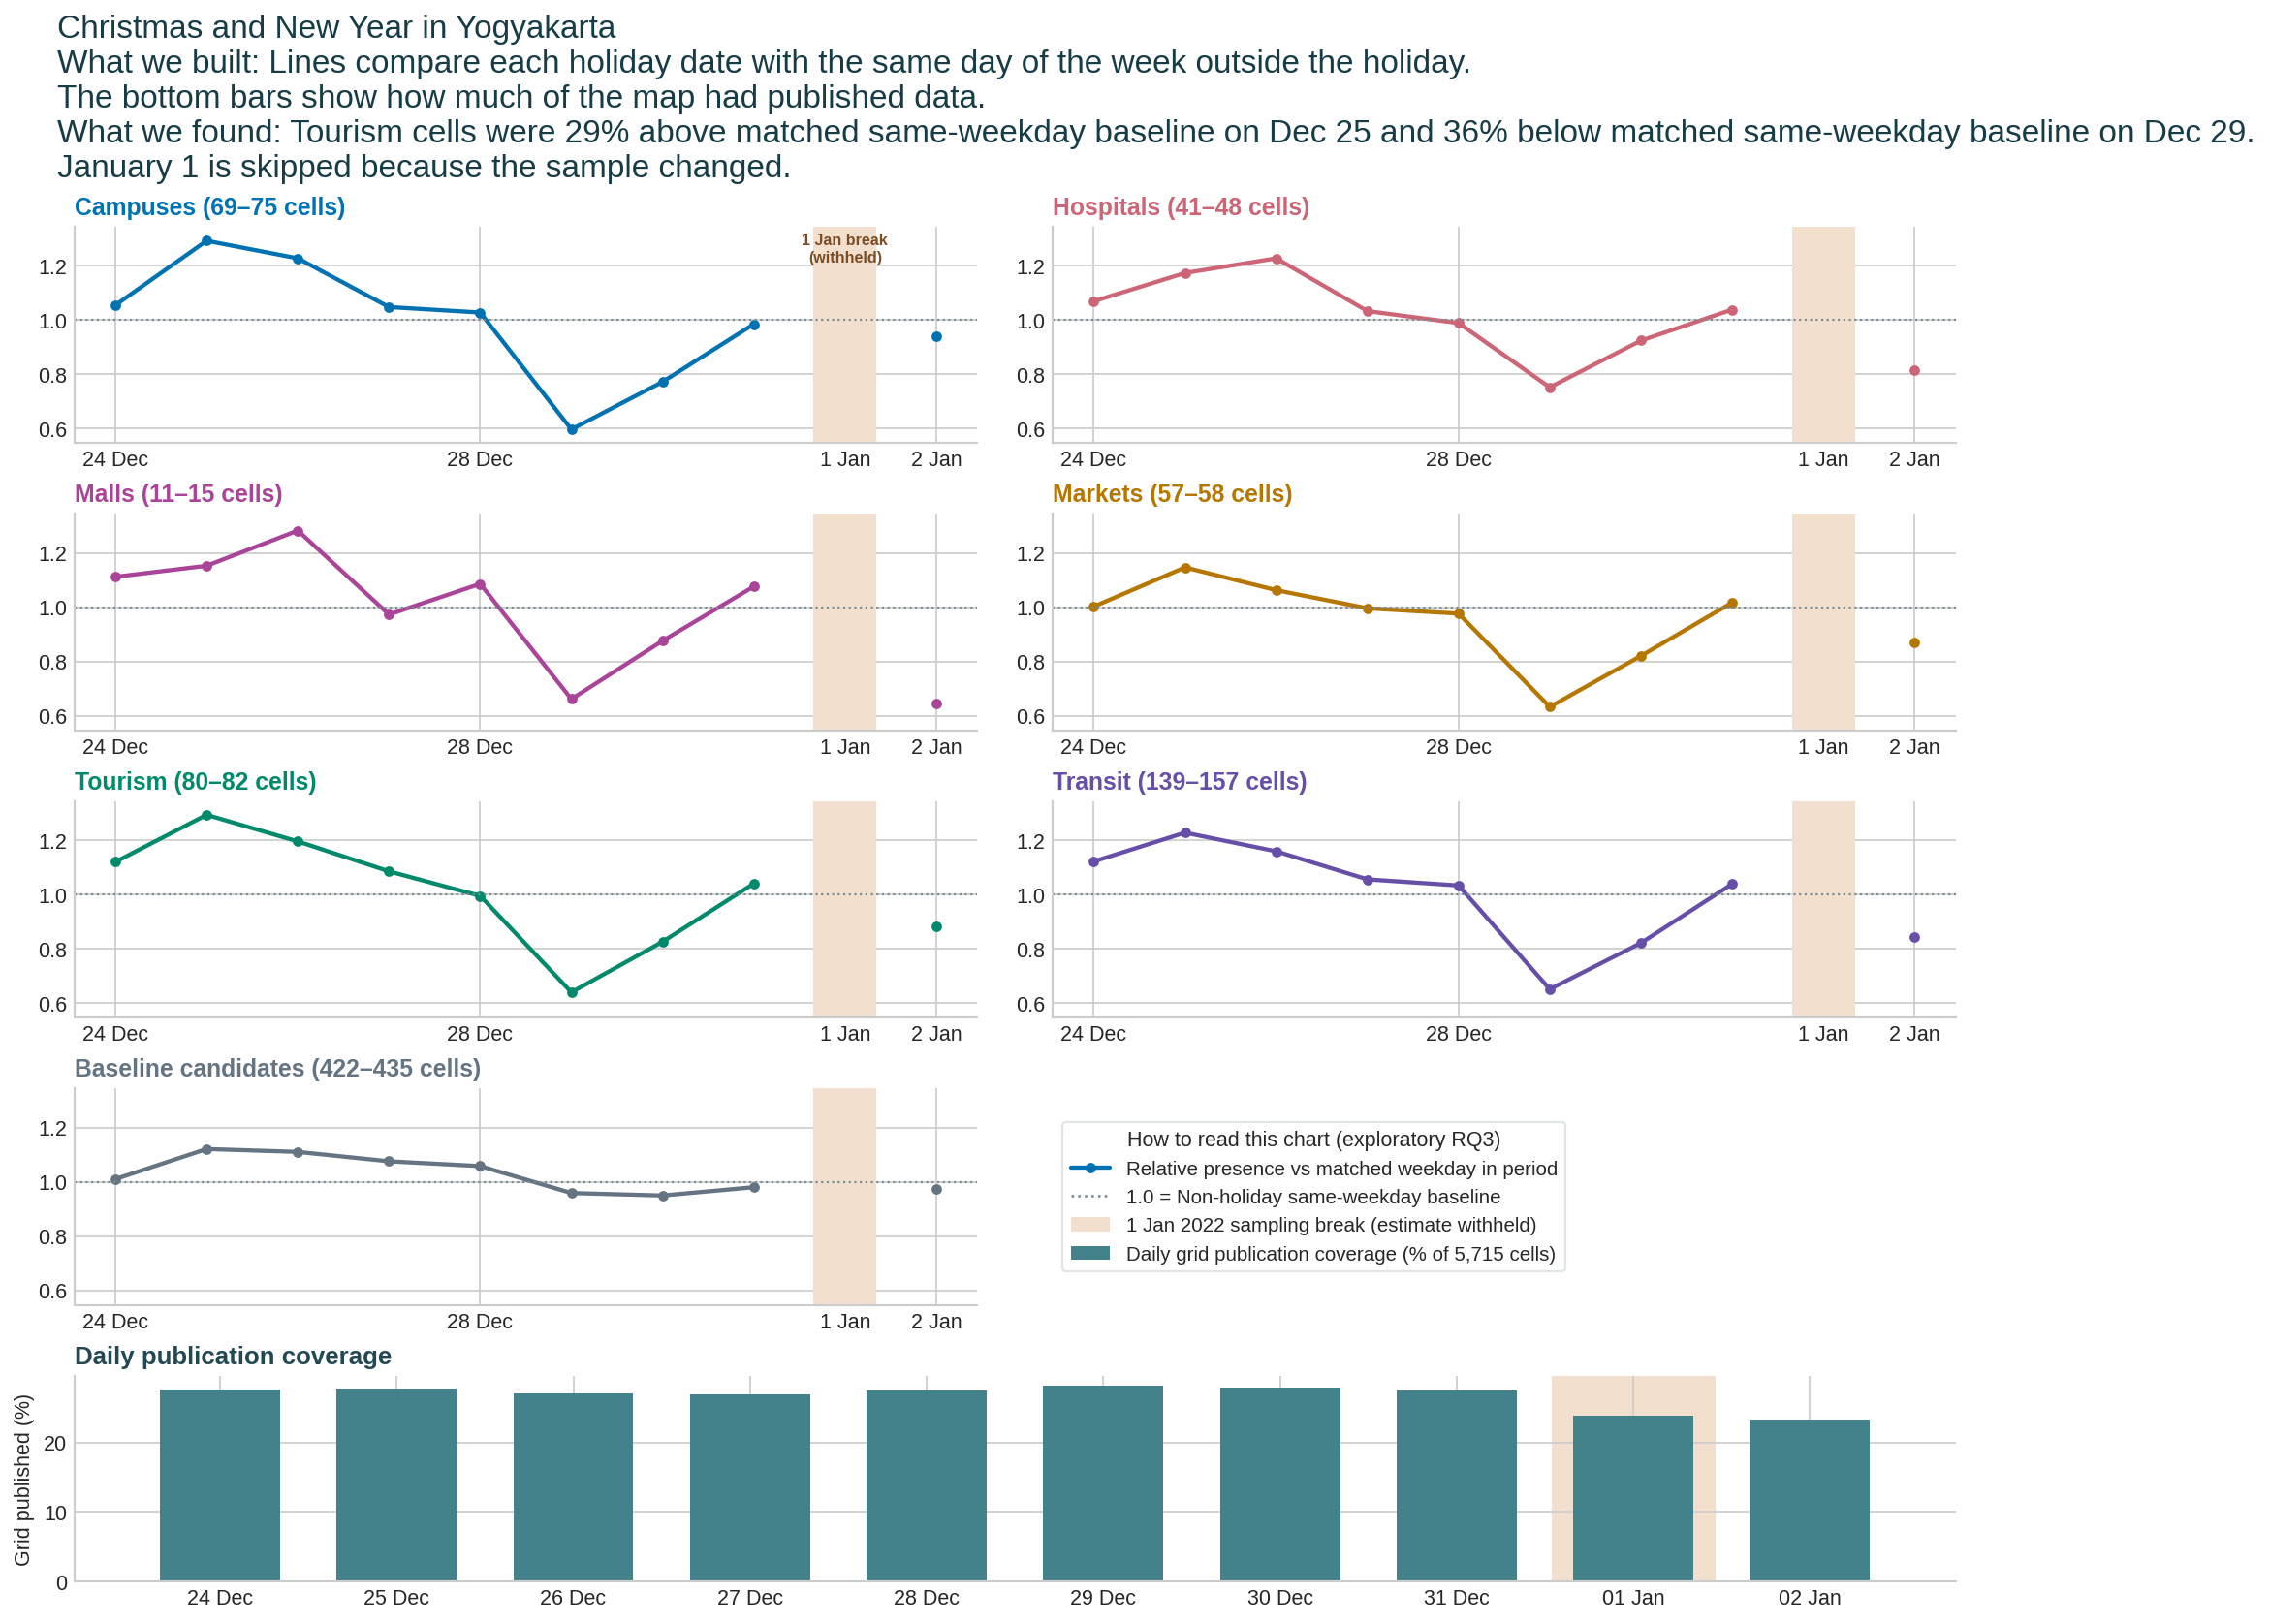

In [ ]:
display(Image(filename=str(nataru_fig)))

**Interpretation.** Tourism cells were **29% above** their matched same-weekday baseline on Christmas Day and **36% below** it on December 29. The line tracks relative device presence. The lower panel shows how much of the grid had published data. Coverage fell from **27.5% to 23.9%** at the January 1 sample break, so the figure withholds that day's estimate. The holiday comparisons are exploratory.


### 4.4 RQ4 Diurnal Pulse
Hour by hour device counts for the ten busiest sub-districts in December 2021. Circles mark each district's peak hour.

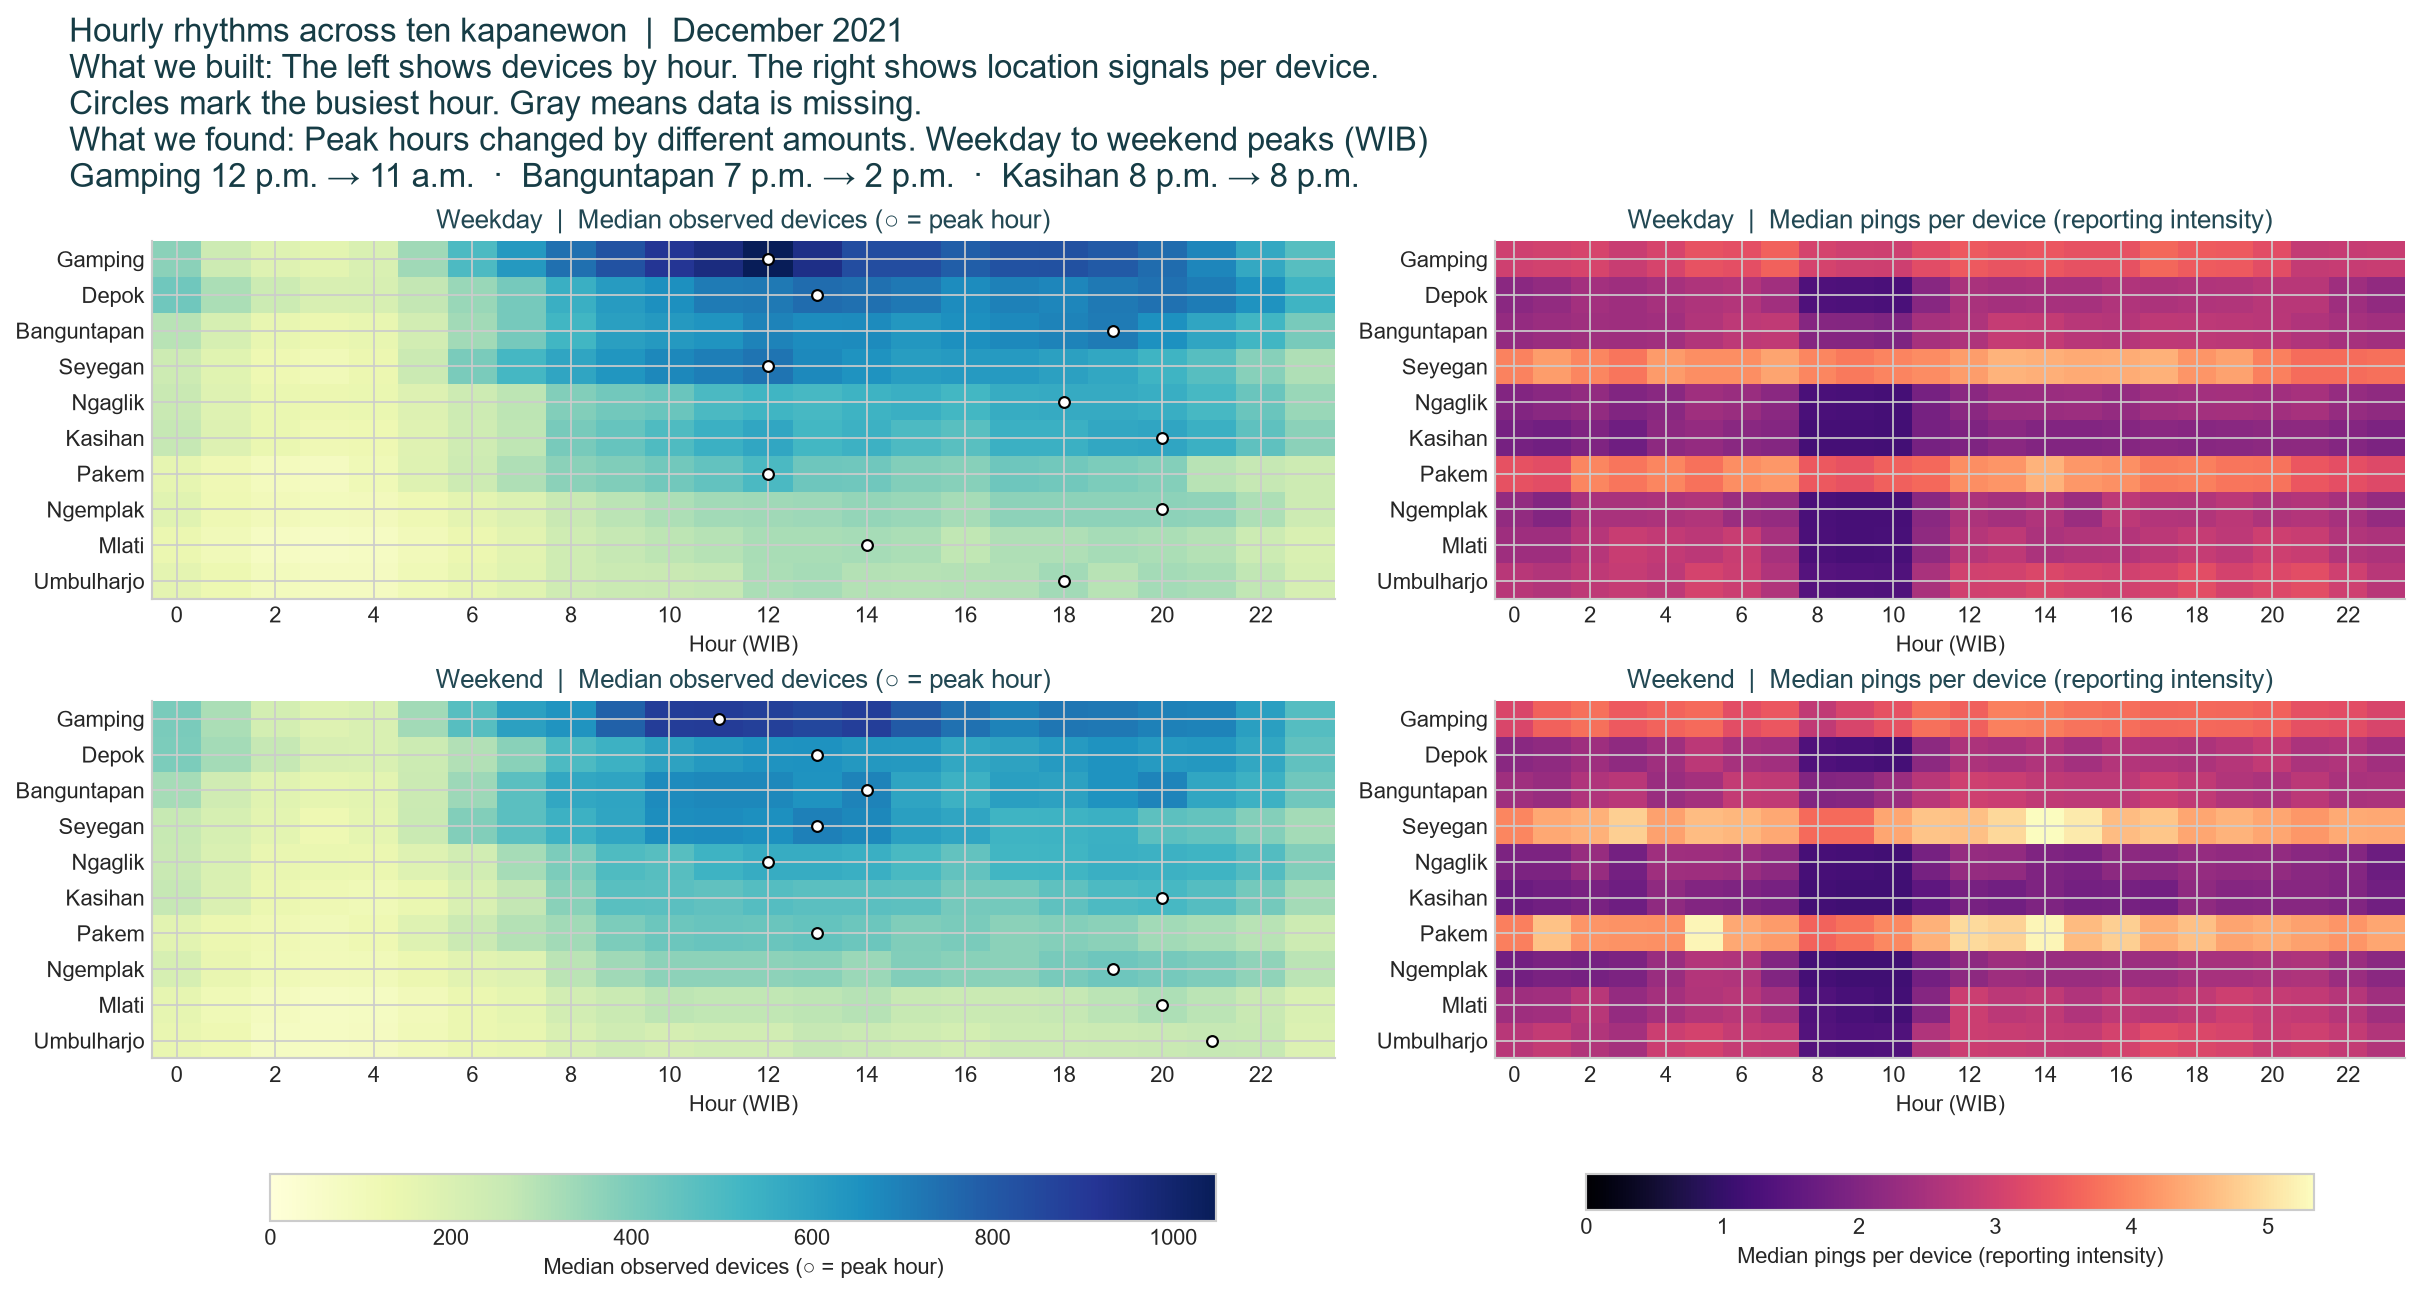

In [ ]:
display(Image(filename=str(hourly_fig)))

**Interpretation.** Follow the circles in the device-count panels to compare peak hours. Banguntapan peaked at **7 p.m. on weekdays** and **2 p.m. on weekends**, a five-hour shift. Gamping moved from **noon to 11 a.m.**, while Kasihan stayed at **8 p.m.** Times are local (WIB). The separate pings-per-device panels show reporting intensity, which can vary independently of the observed device count.


### 4.5 Interactive 500 m map and GitHub Pages

The build cell above generates all four charts and **figures/city_magnets_map.html**. The HTML combines the Silver grid and facility labels with Gold weekday and weekend presence metrics and publication coverage. It embeds Leaflet, administrative boundaries, and major roads for offline use. The optional street basemap requires an internet connection.

**Try the [live GitHub Pages map](https://altafparves.github.io/Human-Mobility/).** The default view is February 1–15, 2022. Click a square to inspect its weekday and weekend presence shares and publication coverage. Switch periods in the layer controls and use **Color by** to see weekday or weekend coverage. Check the number of eligible cells before interpreting the ratio colors.

The next cell checks that the HTML was generated and reports its size.


In [ ]:
assert map_file.is_file() and map_file.stat().st_size > 0, "Run the Role 4 build cell first."
print(f"Generated map: {map_file}")
print(f"Size: {map_file.stat().st_size / 1_000_000:.1f} MB")


**Interpretation.** In the February 1–15 view, **1,628 of 5,715 cells (28.5%)** qualify for the weekday/weekend comparison. Each qualifying cell has at least **90% publication coverage** on both weekdays and weekends. Of those cells, **829** lean weekday, **498** lean weekend, and **301** are near parity. Use the ratio layer to see the direction of the difference, then switch to a coverage layer to see where the data were available. A cell without a published ratio has insufficient coverage or no estimate under the comparison rules.


**Download the HTML from Colab.** Open the **Files** sidebar, go to **Human-Mobility/figures**, and choose **Download** from the menu for **city_magnets_map.html**. Open the downloaded file in a browser. You can also uncomment and run the two lines in the optional download cell below.

**Publish an updated website.** Copy the regenerated **city_magnets_map.html** to the root of the repository's **gh-pages** branch as **index.html**, then commit and push. In GitHub Pages settings, confirm the source branch is **gh-pages** and the folder is **/ (root)**. After deployment, open the live map and test switching periods and clicking a cell. Colab generates the HTML within the notebook session. GitHub Pages publishes the separate website update.


In [ ]:
# Optional Colab download. Uncomment both lines and run this cell.
# from google.colab import files
# files.download(str(map_file))


---
## Closing
Each step depends on the one before it. Altaf's presence share and coverage rule make days comparable. Nalen's deduplicated facility labels say what is in each cell. Rafi's cluster bootstrap and sensitivity checks decide which patterns are trustworthy. Akhnaf's four figures and interactive map show the results, and the five-minute demo video walks through them.

**Limits.** The data covers smartphones with location enabled apps, not everyone. Hidden cells favour busy areas. A 500 m cell can hold several facilities. All results are associations, not causes.

Data: JogjaPulse, Zenodo record 23157460 (CC BY 4.0). Facilities: © OpenStreetMap contributors, ODbL.

Administrative boundaries: [geoBoundaries Indonesia ADM2](https://www.geoboundaries.org/api/current/gbOpen/IDN/ADM2/) (CC BY 3.0 IGO).